In [ ]:
import pandas as pd
train_2014_2019=pd.read_csv('train_2014_2019.csv')

In [ ]:
#create a label if the dataset excess_return higher 0 as 1 and excess_return less than 0 as 0

train_2014_2019['excess_return_label'] = train_2014_2019['excess_return'].apply(lambda x: 1 if x > 0 else 0)
train_2014_2019

,Ticker,TickerType,Company,Traded,Transaction,Trade_Size_USD,Status,Subholding,Description,Name,...,Quiver_Upload_Time,excess_return,State,last_modified,Short,Committees,Industry,Sector,In_SP100,excess_return_label
0,COF,ST,CAPITAL ONE FINANCIAL CORPORATION,2019-12-31,Purchase,1001 - 15000,NEW,ROLLOVER IRA,NaN,Joe Courtney,...,2020-08-05,-9.420175,Connecticut,2023-11-16,NaN,Armed Services; Education,Financial - Credit Services,Financial Services,True,0
1,DOW,ST,Dow Inc.,2019-12-31,Sale (Partial),1001 - 15000,New,NaN,NaN,David Perdue,...,2020-07-26,-113.892488,Georgia,2023-08-28,NaN,Agriculture; Armed Services; Banking; Budget,Chemicals,Basic Materials,True,0
2,ZTS,ST,ZOETIS INC. CLASS A,2019-12-31,Purchase,1001 - 15000,NEW,ROLLOVER IRA,NaN,Joe Courtney,...,2020-08-05,-52.925673,Connecticut,2023-11-16,NaN,Armed Services; Education,Drug Manufacturers - Specialty & Generic,Healthcare,False,0
3,PLD,ST,"PROLOGIS, INC.",2019-12-31,Purchase,1001 - 15000,NEW,ROLLOVER IRA,NaN,Joe Courtney,...,2020-08-05,-57.884624,Connecticut,2023-11-16,NaN,Armed Services; Education,REIT - Industrial,Real Estate,False,0
4,HD,ST,"HOME DEPOT, INC.",2019-12-31,Purchase,1001 - 15000,NEW,ROLLOVER IRA,NaN,Joe Courtney,...,2020-08-05,-3.799756,Connecticut,2023-11-16,NaN,Armed Services; Education,Home Improvement,Consumer Cyclical,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13098,CBL,ST,CBL & Associates Properties Inc. (NYSE),2014-02-24,Sale (Full),100001 - 250000,New,NaN,NaN,Bob Corker,...,2020-07-26,-168.349839,Tennessee,2023-11-14,NaN,Aging; Banking; Foreign Relations,REIT - Retail,Real Estate,False,0
13099,CBL,ST,CBL & Associates Properties Inc. (NYSE),2014-02-24,Sale (Full),500001 - 1000000,New,NaN,NaN,Bob Corker,...,2020-07-26,-168.349839,Tennessee,2023-11-14,NaN,Aging; Banking; Foreign Relations,REIT - Retail,Real Estate,False,0
13100,CBL,ST,CBL & Associates Properties Inc. (NYSE),2014-02-24,Sale (Full),500001 - 1000000,New,NaN,NaN,Bob Corker,...,2020-07-26,-168.349839,Tennessee,2023-11-14,NaN,Aging; Banking; Foreign Relations,REIT - Retail,Real Estate,False,0
13101,CBL,ST,CBL & Associates Properties Inc. (NYSE),2014-02-24,Sale (Full),500001 - 1000000,New,NaN,NaN,Bob Corker,...,2020-07-26,-168.349839,Tennessee,2023-11-14,NaN,Aging; Banking; Foreign Relations,REIT - Retail,Real Estate,False,0


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [00:56:13] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Top 5 Important Features:
           Feature  Importance
1      Transaction    0.245972
6            Party    0.117026
15        In_SP100    0.095110
14          Sector    0.093537
2   Trade_Size_USD    0.072753
8          Chamber    0.057934
0           Ticker    0.057391
13        Industry    0.054209
5            Filed    0.036114
10           State    0.033941


<Figure size 1000x600 with 0 Axes>

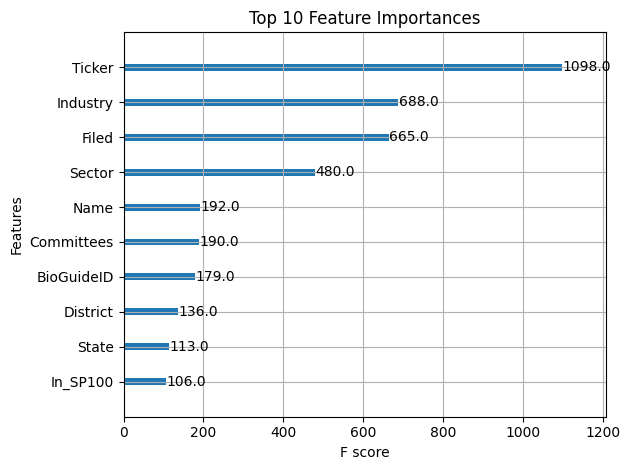

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [00:56:14] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Accuracy: 0.539
Precision: 0.527
Recall: 0.357
F1 Score: 0.426
AUC: 0.547


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier, plot_importance
from imblearn.over_sampling import SMOTE

# Load data
train_df = pd.read_csv("train_2019_2024.csv")
test_df = pd.read_csv("test_2025.csv")

# Define columns to drop
drop_cols = ['Unnamed: 0', 'TickerType', 'Company', 'Traded', 'Status', 'Subholding',
             'Description', 'Quiver_Upload_Time', 'last_modified']

# Prepare features and labels
train_X = train_df.drop(columns=drop_cols + ['excess_return', 'excess_return_label'], errors='ignore')
test_X = test_df.drop(columns=drop_cols + ['excess_return', 'excess_return_label'], errors='ignore')
train_y = train_df['excess_return_label']
test_y = test_df['excess_return_label']

# Encode categorical columns
cat_cols = train_X.select_dtypes(include=['object']).columns
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
train_X[cat_cols] = encoder.fit_transform(train_X[cat_cols].astype(str))
test_X[cat_cols] = encoder.transform(test_X[cat_cols].astype(str))

# use SMOTE to banlace data
smote = SMOTE(random_state=42)
train_X_resampled, train_y_resampled = smote.fit_resample(train_X, train_y)

# training with XGBoost
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(train_X_resampled, train_y_resampled)

# show the importances of features
importances = model.feature_importances_
features = train_X.columns
importance_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("\nTop 5 Important Features:")
print(importance_df.head(10))

plt.figure(figsize=(10, 6))
plot_importance(model, max_num_features=10, importance_type='weight')
plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()

# feature selection and retrain the model
selector = SelectFromModel(model, threshold='median', prefit=True)
train_X_selected = selector.transform(train_X_resampled)
test_X_selected = selector.transform(test_X)

model_selected = XGBClassifier(
    use_label_encoder=False,
    eval_metric='logloss',
    n_estimators=100,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8
)
model_selected.fit(train_X_selected, train_y_resampled)

# evaluation
preds = model_selected.predict(test_X_selected)
preds_proba = model_selected.predict_proba(test_X_selected)[:, 1]

accuracy = accuracy_score(test_y, preds)
precision = precision_score(test_y, preds)
recall = recall_score(test_y, preds)
f1 = f1_score(test_y, preds)
auc = roc_auc_score(test_y, preds_proba)

print(f"\nAccuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"AUC: {auc:.3f}")



In [ ]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import SelectFromModel
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Load data
train_df = pd.read_csv("train_2015_2020.csv")
test_df = pd.read_csv("test_2021.csv")

# Define columns to drop (excluding specified useful features)
drop_cols = ['Unnamed: 0', 'TickerType', 'Company', 'Traded', 'Status', 'Subholding',
             'Description', 'Quiver_Upload_Time', 'last_modified']

# Prepare features and labels
train_X = train_df.drop(columns=drop_cols + ['excess_return', 'excess_return_label'], errors='ignore')
test_X = test_df.drop(columns=drop_cols + ['excess_return', 'excess_return_label'], errors='ignore')
train_y = train_df['excess_return_label']
test_y = test_df['excess_return_label']

# Encode categorical columns
cat_cols = train_X.select_dtypes(include=['object']).columns
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
train_X[cat_cols] = encoder.fit_transform(train_X[cat_cols].astype(str))
test_X[cat_cols] = encoder.transform(test_X[cat_cols].astype(str))

# Train initial XGBoost model
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(train_X, train_y)

# Feature selection based on importance
selector = SelectFromModel(model, threshold='median', prefit=True)
train_X_selected = selector.transform(train_X)
test_X_selected = selector.transform(test_X)

# Retrain model with optimized parameters
model_selected = XGBClassifier(
    use_label_encoder=False,
    eval_metric='logloss',
    n_estimators=100,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8
)
model_selected.fit(train_X_selected, train_y)

# Predict and evaluate
preds = model_selected.predict(test_X_selected)
preds_proba = model_selected.predict_proba(test_X_selected)[:, 1]

# Compute and print metrics
accuracy = accuracy_score(test_y, preds)
precision = precision_score(test_y, preds)
recall = recall_score(test_y, preds)
f1 = f1_score(test_y, preds)
auc = roc_auc_score(test_y, preds_proba)

print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"AUC: {auc:.3f}")



/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [01:44:02] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy: 0.754
Precision: 0.769
Recall: 0.439
F1 Score: 0.559
AUC: 0.742


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SelectFromModel was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [01:44:02] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


In [ ]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from sklearn.utils import resample
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Load data
train_df = pd.read_csv("/content/train_2015_2020.csv")
test_df = pd.read_csv("test_2021.csv")

# Convert dates
train_df['Traded'] = pd.to_datetime(train_df['Traded'], errors='coerce')
test_df['Traded'] = pd.to_datetime(test_df['Traded'], errors='coerce')

# Filter training data: 2018–2019
train_df = train_df[(train_df['Traded'] >= '2019-01-01') & (train_df['Traded'] < '2020-12-31')]

# Add temporal features
for df in [train_df, test_df]:
    df['month'] = df['Traded'].dt.month
    df['quarter'] = df['Traded'].dt.quarter

# Define features to keep
feature_cols = ['Ticker', 'Name', 'Short', 'Transaction', 'Trade_Size_USD', 'State',
                'Committees', 'Industry', 'Sector', 'In_SP100', 'month', 'quarter']

# Oversample the minority class
majority = train_df[train_df.excess_return_label == 0]
minority = train_df[train_df.excess_return_label == 1]
minority_upsampled = resample(minority, replace=True, n_samples=len(majority), random_state=42)
train_df_oversampled = pd.concat([majority, minority_upsampled])

# Prepare training data
train_X = train_df_oversampled[feature_cols].copy()
train_y = train_df_oversampled['excess_return_label']

# Encode categorical columns
cat_cols = train_X.select_dtypes(include=['object', 'bool']).columns
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
train_X[cat_cols] = encoder.fit_transform(train_X[cat_cols].astype(str))

# Train XGBoost model
model = XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                      n_estimators=100, max_depth=3, subsample=0.8, colsample_bytree=0.8)
model.fit(train_X, train_y)

# Define evaluation function
def evaluate_subset(test_subset):
    test_subset = test_subset.copy()
    test_subset['month'] = test_subset['Traded'].dt.month
    test_subset['quarter'] = test_subset['Traded'].dt.quarter
    test_X = test_subset[feature_cols].copy()
    test_y = test_subset['excess_return_label']
    test_X[cat_cols] = encoder.transform(test_X[cat_cols].astype(str))
    preds = model.predict(test_X)
    proba = model.predict_proba(test_X)[:, 1]
    return {
        "accuracy": accuracy_score(test_y, preds),
        "precision": precision_score(test_y, preds),
        "recall": recall_score(test_y, preds),
        "f1": f1_score(test_y, preds),
        "auc": roc_auc_score(test_y, proba)
    }

# Evaluate on subsets of 2020
test_1m = test_df[test_df['Traded'] < '2021-02-01']
test_3m = test_df[test_df['Traded'] < '2021-04-01']
test_6m = test_df[test_df['Traded'] < '2021-07-01']

metrics_1m = evaluate_subset(test_1m)
metrics_3m = evaluate_subset(test_3m)
metrics_6m = evaluate_subset(test_6m)

print("📅 First Month (Jan 2020):", metrics_1m)
print("📅 First 3 Months (Q1 2020):", metrics_3m)
print("📅 First 6 Months (H1 2020):", metrics_6m)



/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [02:09:49] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


📅 First Month (Jan 2020): {'accuracy': 0.783303730017762, 'precision': 0.6528497409326425, 'recall': 0.6961325966850829, 'f1': 0.6737967914438503, 'auc': np.float64(0.8081990685834949)}
📅 First 3 Months (Q1 2020): {'accuracy': 0.7469670710571924, 'precision': 0.6034755134281201, 'recall': 0.671353251318102, 'f1': 0.6356073211314476, 'auc': np.float64(0.7971559852263687)}
📅 First 6 Months (H1 2020): {'accuracy': 0.7406465673810388, 'precision': 0.5833333333333334, 'recall': 0.6984304932735426, 'f1': 0.6357142857142857, 'auc': np.float64(0.8013692069695882)}
